# Role 2 (Nalen) Visual Playground : Geospatial Engineering and Facility Deduplication

This notebook shows what Role 2 built and why. It only reads the files made by `python -m src.spatial_join`, so all real logic stays in `src/spatial_join.py`.

**The question Role 2 answers:** which facilities are inside each 500 m grid cell?

JogjaPulse tells us how many devices were in each cell, but not what is inside the cell. OpenStreetMap (OSM) knows where campuses, hospitals, malls, markets, tourism sites and transit stops are. Role 2 connects the two.

**The pipeline in this notebook:**
1. Look at the raw OSM drawings and see the problem.
2. Deduplicate them into real world sites.
3. Place every site on the grid and measure the overlap.
4. Label every cell as single category, mixed use, or no selected facility.
5. Hand the final table to Rafi (Role 3).

> Before running: `python -m src.ingest`, `python -m src.clean_temporal`, then `python -m src.spatial_join`.

In [1]:
import json
import sys
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.spatial_join import build_grid_polygons

SILVER = ROOT / "data" / "silver"
grid = build_grid_polygons(pd.read_parquet(SILVER / "grid_cells_unique.parquet"))
raw = gpd.read_parquet(SILVER / "osm_facilities_parsed.parquet")
sites = gpd.read_parquet(SILVER / "facilities_dedup.parquet")
links = pd.read_parquet(SILVER / "cell_facility_links.parquet")
cells = pd.read_parquet(SILVER / "grid_facilities.parquet")
summary = json.loads((SILVER / "spatial_join_summary.json").read_text(encoding="utf-8"))
dedup_log = json.loads((SILVER / "facilities_dedup_log.json").read_text(encoding="utf-8"))

COLORS = {"education_campus": "#1f77b4", "healthcare_hospital": "#d62728", "commercial_mall": "#9467bd",
          "traditional_market": "#ff7f0e", "tourism_site": "#2ca02c", "transit_hub": "#7f7f7f"}
pd.set_option("display.max_colwidth", 60)
print(f"grid cells: {len(grid):,} | raw OSM features: {len(raw):,} | sites: {len(sites):,} | links: {len(links):,}")

grid cells: 5,715 | raw OSM features: 2,357 | sites: 1,276 | links: 1,507


## 1. The problem: one place, many drawings

OSM volunteers draw the same place in many ways. A campus can be one big outline (a polygon) plus a point for every faculty, museum and bus stop inside it. A station can be one outline plus a separate drawing for each platform.

If we counted every drawing, UGM would count as dozens of campuses. The map below shows the raw OSM drawings around UGM and RSUP Dr. Sardjito. Polygons are outlines and dots are points. Colours show the study category.

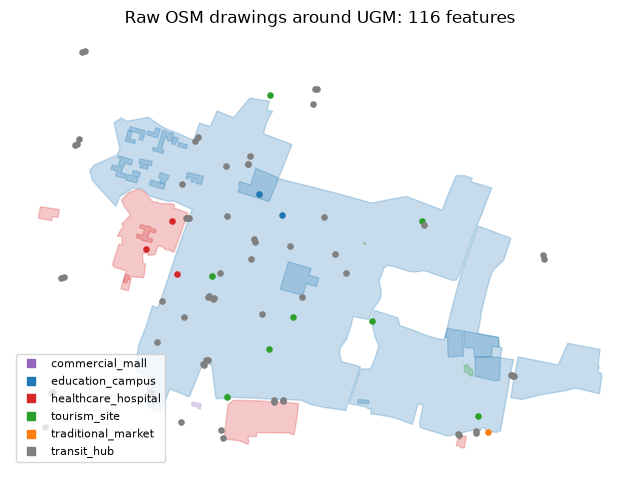

In [2]:
ugm = sites.loc[sites["name"] == "Universitas Gadjah Mada"].iloc[0]
xmin, ymin, xmax, ymax = ugm.geometry.buffer(300).bounds

def window(gdf):
    return gdf.cx[xmin:xmax, ymin:ymax]

def draw_features(ax, gdf, category_col):
    for cat, part in gdf.groupby(category_col):
        polys = part[part.geom_type.isin(["Polygon", "MultiPolygon"])]
        others = part[~part.geom_type.isin(["Polygon", "MultiPolygon"])]
        if len(polys):
            polys.plot(ax=ax, facecolor=COLORS[cat], edgecolor=COLORS[cat], alpha=0.25)
        if len(others):
            others.plot(ax=ax, color=COLORS[cat], markersize=14)
        ax.plot([], [], "s", color=COLORS[cat], label=cat)

raw_ugm = window(raw.explode("categories").rename(columns={"categories": "category"}))
fig, ax = plt.subplots(figsize=(8, 8))
draw_features(ax, raw_ugm, "category")
ax.set_title(f"Raw OSM drawings around UGM: {len(raw_ugm)} features")
ax.legend(loc="lower left", fontsize=8)
ax.set_axis_off()
plt.show()

## 2. Deduplication: from drawings to real world sites

We group drawings of the same category that describe one real place into one **site**. Two drawings are linked when any of these rules holds:

| Rule | Meaning | Example |
| :--- | :--- | :--- |
| contained | One drawing sits inside the other's outline | Faculty points inside the UGM campus |
| same name | Same name and within 500 m | The 11 buildings of Pasar Rogobangsan |
| transit | Two transit drawings within 20 m | A bus stop drawn as a sign, a stop position and a platform |

Links chain together, so if A links to B and B links to C, all three become one site. Two old train stops that are now attractions (Stasiun Trem Gamplong and Eks Halte Mlati) count as tourism only, because the crowd there is visitors and not commuters.

Same name drawings that are far apart stay separate and go into the log for review. The two "Pasar Turi" markets 36 km apart are an example.

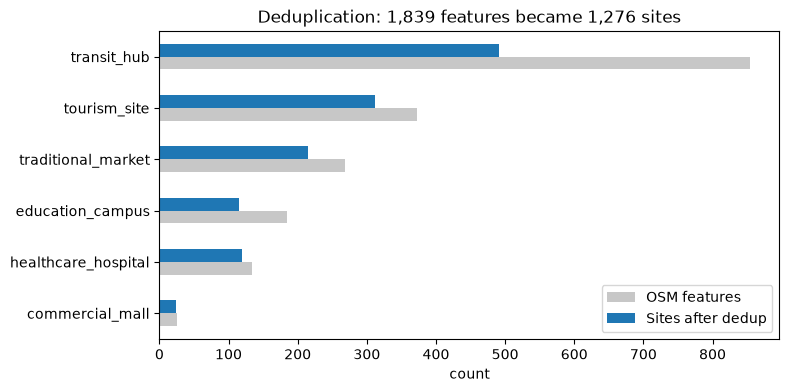

Links made by each rule: {'same_name': 424, 'transit': 318, 'contained': 191}
Same name groups kept apart for review: 11


In [3]:
before = pd.Series(dedup_log["features_by_category"])
after = pd.Series(dedup_log["sites_by_category"])
compare = pd.DataFrame({"OSM features": before, "Sites after dedup": after}).sort_values("OSM features")

ax = compare.plot.barh(figsize=(8, 4), color=["#c7c7c7", "#1f77b4"])
ax.set_title(f"Deduplication: {before.sum():,} features became {after.sum():,} sites")
ax.set_xlabel("count")
plt.show()

print("Links made by each rule:", dedup_log["links_by_rule"])
print("Same name groups kept apart for review:", len(dedup_log["ambiguous_same_name_kept_apart"]))

Here is the same area after deduplication. The UGM campus and its faculty points are now one site, and each bus stop is one site instead of two or three drawings.

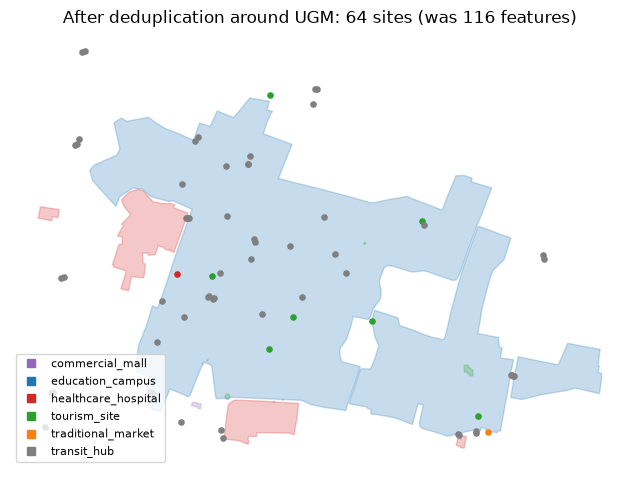

,site_id,name,category,n_osm_features,area_m2
19,commercial_mall_0019,Pakuwon Mall Yogyakarta,commercial_mall,1,26300.0
134,education_campus_0134,Universitas Gadjah Mada,education_campus,18,1619673.0
234,healthcare_hospital_0234,RSUP Dr. Sardjito,healthcare_hospital,5,98820.0
662,traditional_market_0662,Pasar Rogobangsan,traditional_market,11,1123.0
1251,transit_hub_1251,Yogyakarta,transit_hub,16,5057.0


In [4]:
sites_ugm = window(sites)
fig, ax = plt.subplots(figsize=(8, 8))
draw_features(ax, sites_ugm, "category")
ax.set_title(f"After deduplication around UGM: {len(sites_ugm)} sites (was {len(raw_ugm)} features)")
ax.legend(loc="lower left", fontsize=8)
ax.set_axis_off()
plt.show()

landmarks = ["Universitas Gadjah Mada", "RSUP Dr. Sardjito", "Yogyakarta", "Pasar Rogobangsan", "Pakuwon Mall Yogyakarta"]
sites.loc[sites["name"].isin(landmarks), ["site_id", "name", "category", "n_osm_features", "area_m2"]].round(0)

## 3. The spatial join: which cells does each site reach?

We rebuild every JogjaPulse cell as an exact 500 m square in UTM zone 49S (EPSG:32749), a map projection measured in metres. Then we place each site on the grid:

* **Polygons** are cut by the grid lines, and we keep the area that falls inside each cell.
* **Points** go to the one cell that contains them. A point exactly on a border goes to one cell only, following the dataset's own grid rule.
* Only the 5,715 published cells count.

A big site reaches many cells. The map shows how much of each cell the UGM campus covers.

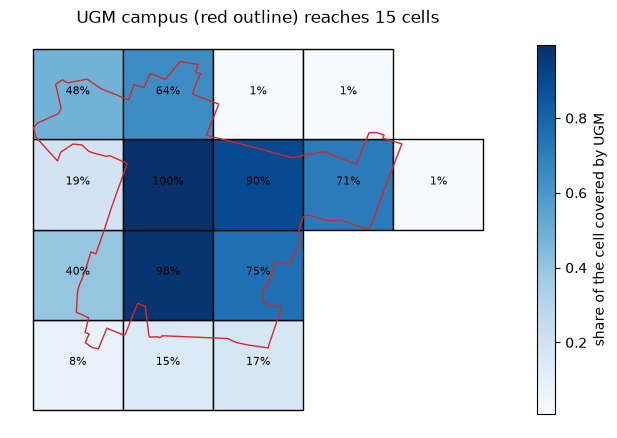

In [5]:
ugm_links = links[links["site_id"] == ugm["site_id"]].merge(grid[["cell_id", "geometry"]], on="cell_id")
ugm_links = gpd.GeoDataFrame(ugm_links, geometry="geometry", crs=grid.crs)

fig, ax = plt.subplots(figsize=(8, 8))
ugm_links.plot(ax=ax, column="overlap_share_of_cell", cmap="Blues", edgecolor="black", legend=True,
               legend_kwds={"label": "share of the cell covered by UGM", "shrink": 0.6})
gpd.GeoSeries([ugm.geometry], crs=grid.crs).boundary.plot(ax=ax, color="#d62728", linewidth=1)
for _, r in ugm_links.iterrows():
    p = r.geometry.centroid
    ax.annotate(f"{r.overlap_share_of_cell:.0%}", (p.x, p.y), ha="center", fontsize=8)
ax.set_title(f"UGM campus (red outline) reaches {len(ugm_links)} cells")
ax.set_axis_off()
plt.show()

### Slivers: when does a facility really count in a cell?

Some overlaps are tiny. In the cell in the middle of UGM, a 25 m² corner of the RSUP Dr. Sardjito outline crosses the border. That is smaller than a parking spot. If we counted it, the cell would look like a campus plus hospital mixed use cell.

So a polygon only counts in a cell when one of these is true:
* it covers at least **5% of the cell** (12,500 m²), so big sites count where they really take space
* at least **50% of the site** is in that cell, so small buildings still count in their own cell
* it is the site's **home cell**, the cell holding its largest piece, as long as most of the site is in published cells. This keeps sites that are split into many small pieces.

Points always count. Slivers are not deleted. They stay in the links table with `counts_for_cell = False`.

In [6]:
names = sites.set_index("site_id")["name"]
example = links[links["cell_id"] == "E862_N18282"].assign(name=lambda d: d["site_id"].map(names))
example[["name", "category", "link_kind", "overlap_m2", "overlap_share_of_cell", "counts_for_cell"]].round(3)

,name,category,link_kind,overlap_m2,overlap_share_of_cell,counts_for_cell
756,Universitas Gadjah Mada,education_campus,polygon,248995.950,0.996,True
757,RSUP Dr. Sardjito,healthcare_hospital,polygon,25.452,0.000,False
758,Bio-Paleoanthropology Museum,tourism_site,point,0.000,0.000,True
759,Halte RS Sardjito (Timur),transit_hub,point,0.000,0.000,True
760,Halte GSP,transit_hub,point,0.000,0.000,True
761,Halte Jalan Medika,transit_hub,point,0.000,0.000,True
762,Halte F. MIPA,transit_hub,point,0.000,0.000,True
763,GSP UGM (Barat),transit_hub,point,0.000,0.000,True


In [7]:
poly_links = links[links["link_kind"] == "polygon"]
print(f"Polygon links: {len(poly_links):,} | counted: {poly_links['counts_for_cell'].sum():,} | slivers not counted: {(~poly_links['counts_for_cell']).sum():,}")

Polygon links: 785 | counted: 603 | slivers not counted: 182


## 4. Cell classes: single category, mixed use, or no selected facility

Now every cell gets a label based on the five destination categories (campus, hospital, mall, market, tourism):

* **single_category**: exactly one destination category
* **mixed_use**: two or more, for example a campus next to a museum
* **no_selected_facility**: none of the five. These cells can still hold housing, farmland, roads or unmapped places.

**Transit is a separate flag.** Bus stops are almost everywhere in the city. If they counted like the others, most urban cells would look mixed use, and the category comparison would lose meaning. So transit gets its own `has_transit_hub` column but does not change the class.

**Baseline candidates** are no selected facility cells within 2 km of a facility cell. They are nearby places to compare against, so the comparison is not city centre against empty farmland.

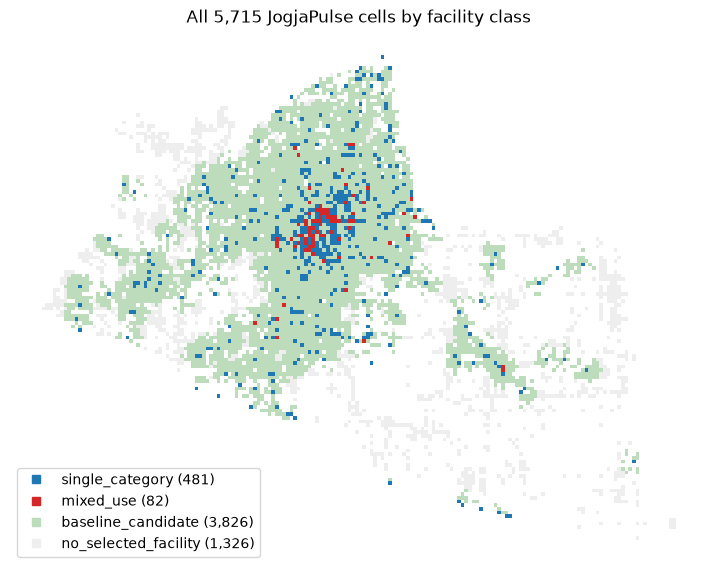

In [8]:
cells_geo = gpd.GeoDataFrame(cells, geometry=build_grid_polygons(cells).geometry, crs=grid.crs)
cells_geo["map_class"] = cells_geo["cell_class"].where(
    cells_geo["cell_class"] != "no_selected_facility",
    cells_geo["is_baseline_candidate"].map({True: "baseline_candidate", False: "no_selected_facility"}))
CLASS_COLORS = {"single_category": "#1f77b4", "mixed_use": "#d62728",
                "baseline_candidate": "#bcdcbc", "no_selected_facility": "#eeeeee"}

fig, ax = plt.subplots(figsize=(9, 9))
for cls, color in CLASS_COLORS.items():
    cells_geo[cells_geo["map_class"] == cls].plot(ax=ax, color=color, label=cls)
    ax.plot([], [], "s", color=color, label=f"{cls} ({(cells_geo['map_class'] == cls).sum():,})")
ax.set_title("All 5,715 JogjaPulse cells by facility class")
handles, labels = ax.get_legend_handles_labels()
ax.legend([h for h, l in zip(handles, labels) if "(" in l], [l for l in labels if "(" in l], loc="lower left")
ax.set_axis_off()
plt.show()

Rafi will mostly use well covered cells, the ones that pass the 90% publication coverage rule from Role 1. Here is how many cells of each class survive that rule, and how many cells each category reaches.

In [9]:
coverage = pd.read_parquet(SILVER / "mobility_daily_clean.parquet", columns=["cell_id", "pass_90_primary_window"])
coverage = coverage.groupby("cell_id")["pass_90_primary_window"].first()
cells_cov = cells.join(coverage, on="cell_id")

class_table = pd.DataFrame({
    "all cells": cells_cov["cell_class"].value_counts(),
    "pass 90% coverage": cells_cov.loc[cells_cov["pass_90_primary_window"], "cell_class"].value_counts(),
})
class_table.loc["baseline_candidate"] = [cells_cov["is_baseline_candidate"].sum(),
                                         (cells_cov["is_baseline_candidate"] & cells_cov["pass_90_primary_window"]).sum()]
display(class_table)
pd.DataFrame(summary["per_category"]).T

,all cells,pass 90% coverage
cell_class,,
no_selected_facility,5152,275
single_category,481,135
mixed_use,82,60
baseline_candidate,3826,257


,distinct_facilities,cells,single_category_cells
education_campus,115.0,117.0,80.0
healthcare_hospital,118.0,115.0,87.0
commercial_mall,24.0,21.0,11.0
traditional_market,215.0,180.0,132.0
tourism_site,311.0,233.0,171.0
transit_hub,490.0,275.0,NaN


## 5. Interactive map

Hover over a cell to see its class and facility names. To keep the map light, it shows facility cells and the baseline candidates that pass the 90% coverage rule.

> GitHub does not run the JavaScript behind this map, so it looks empty there. Open the notebook in Jupyter or VS Code to see it.

In [10]:
show = cells_geo[(cells_geo["cell_class"] != "no_selected_facility")
                 | (cells_geo["is_baseline_candidate"] & cells_geo["cell_id"].map(coverage))].copy()
show["facilities"] = show["facility_names"].map(lambda n: ", ".join(list(n)[:8]) or "none")
show = show[["cell_id", "map_class", "primary_category", "facilities", "geometry"]].to_crs("EPSG:4326")

m = folium.Map(location=[-7.80, 110.37], zoom_start=12, tiles="cartodbpositron")
folium.GeoJson(
    show,
    style_function=lambda f: {"fillColor": CLASS_COLORS[f["properties"]["map_class"]], "color": "#555",
                              "weight": 0.3, "fillOpacity": 0.6},
    tooltip=folium.GeoJsonTooltip(fields=["cell_id", "map_class", "primary_category", "facilities"]),
).add_to(m)
m

D:\Rekdat Final Project\Human-Mobility\.venv\Lib\site-packages\folium\raster_layers.py:129: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 6. What Rafi (Role 3) gets

The main output is `data/silver/grid_facilities.parquet`, with one row for each of the 5,715 cells. Rafi joins it to `mobility_daily_clean.parquet` on `cell_id`.

| Column | Meaning |
| :--- | :--- |
| `n_<category>`, `has_<category>` | How many distinct sites of that category count in the cell, and whether there is at least one |
| `overlap_m2_<category>` | Polygon area of that category inside the cell |
| `n_categories`, `cell_class` | Number of destination categories, and the single, mixed or none label |
| `primary_category` | A display label for maps (the category with the most area). Analysis should use the `has_` columns |
| `site_ids`, `in_multicell_site` | Which sites are in the cell. A site like UGM spans 15 cells, so those cells share devices and should be one cluster when computing uncertainty |
| `dist_to_facility_cell_m`, `is_baseline_candidate` | Distance to the nearest facility cell, and the 2 km baseline flag |

In [11]:
cells[cells["cell_class"] != "no_selected_facility"].head(5)

,cell_id,x_min_utm,y_min_utm,centroid_lon,centroid_lat,x_max_utm,y_max_utm,n_education_campus,has_education_campus,overlap_m2_education_campus,...,has_transit_hub,overlap_m2_transit_hub,n_categories,cell_class,primary_category,site_ids,facility_names,in_multicell_site,dist_to_facility_cell_m,is_baseline_candidate
63,E795_N18252,397500,9126000,110.072391,-7.903559,398000,9126500,0,False,0.0,...,False,0.0,1,single_category,healthcare_hospital,[healthcare_hospital_0249],[],False,0.0,False
74,E796_N18249,398000,9124500,110.076896,-7.917136,398500,9125000,0,False,0.0,...,False,0.0,1,single_category,tourism_site,[tourism_site_0453],[Pantai Glagah],False,0.0,False
79,E796_N18256,398000,9128000,110.076966,-7.885480,398500,9128500,0,False,0.0,...,False,0.0,1,single_category,traditional_market,[traditional_market_0641],[Pasar Temon],False,0.0,False
84,E796_N18261,398000,9130500,110.077016,-7.862869,398500,9131000,0,False,0.0,...,False,0.0,1,single_category,tourism_site,[tourism_site_0373],[Gunung Suru Sukorini],False,0.0,False
189,E804_N18259,402000,9129500,110.113279,-7.871992,402500,9130000,0,False,0.0,...,False,0.0,1,single_category,tourism_site,[tourism_site_0434],[Eks Stasiun Pakualam],False,0.0,False


In [12]:
example_join = pd.read_parquet(SILVER / "mobility_daily_clean.parquet",
                               columns=["cell_id", "date_wib", "n_maids", "published_presence_share_pct"])
example_join = example_join.merge(cells[["cell_id", "cell_class", "has_education_campus", "has_transit_hub"]], on="cell_id")
example_join.head()

,cell_id,date_wib,n_maids,published_presence_share_pct,cell_class,has_education_campus,has_transit_hub
0,E786_N18255,2021-12-01 00:00:00+07:00,9,0.017109,no_selected_facility,False,False
1,E789_N18259,2021-12-01 00:00:00+07:00,7,0.013307,no_selected_facility,False,False
2,E790_N18255,2021-12-01 00:00:00+07:00,17,0.032318,no_selected_facility,False,False
3,E791_N18254,2021-12-01 00:00:00+07:00,5,0.009505,no_selected_facility,False,False
4,E792_N18252,2021-12-01 00:00:00+07:00,20,0.038021,no_selected_facility,False,False


## 7. Known limits

* **Current OSM snapshot.** The historical 2021 query timed out, so we use a current extract. No study facility has a `start_date` of 2022 or later, but places that closed before today may be missing.
* **Cell level, not building level.** A cell with a mall and a market cannot be split. That is why mixed use cells stay explicit.
* **Large tourism areas absorb what is inside them.** A big outline like the Ratu Boko area becomes one site, so attraction counts are conservative.
* **Baseline is distance only.** Matching on coverage and earlier activity needs the mobility data, so Rafi does that part.
* **Association, not causation.** A device in a campus cell did not necessarily visit the campus.

Questions about Role 2 go to **Nalen**.